[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/isocan/ML-accelerated-ORR/blob/main/notebooks/02_stageI_eqv2_trajectory_screening.ipynb)

# Stage I: OC20/EquiformerV2 trajectory screening and adsorption-site analysis

This notebook accompanies the article *Multi-Fidelity Machine-Learning Screening of
Bimetallic Oxygen Reduction Catalysts across MLIP–DFT Workflows*. It reproduces the
Stage I screening of the OC20/EquiformerV2 (EqV2) relaxation trajectories for
O$^{*}$, OH$^{*}$, and OOH$^{*}$:

1. **Quality control** of every trajectory: readable endpoints, consistent atom order
   and cell, correct adsorbate stoichiometry, and a final maximum force below 0.05 eV/Å.
2. **Anomaly detection** with the FairChem `DetectTrajAnomaly` checks for adsorbate
   dissociation, adsorbate desorption, surface reconstruction, and intercalation.
3. **Adsorption-site assignment** from periodic oxygen–slab first-shell contacts
   (top, bridge, threefold, fourfold, or irregular coordination).
4. **Selection of the lowest-energy configuration** for each slab–adsorbate system.
   These global minima are the geometries evaluated by single-point DFT (SP-DFT).

The notebook reads the geometries, energies, and forces stored in the trajectories.
It runs on a CPU and needs neither an EqV2 checkpoint nor a GPU.

## Expected results

Running the notebook on the complete archive gives the following numbers, which are
the ones reported in the article and its Supporting Information:

| Quantity | Value |
|---|---|
| Slab–adsorbate folders (556 surfaces × 3 adsorbates, including Pt(111) = mp-126_111) | 1,668 |
| Trajectories screened | 72,391 |
| Validated trajectories | 48,667 |
| Systems with a validated global minimum (O$^{*}$ 556, OH$^{*}$ 555, OOH$^{*}$ 543) | 1,654 |
| Systems with no validated trajectory (SI table of anomalous systems) | 14 |
| Bimetallic surfaces with a complete O$^{*}$/OH$^{*}$/OOH$^{*}$ set | 542 |

The DFT quality control of the 542 complete sets, which leaves the 517 surfaces of the
CHE analysis, is described in the Supporting Information. The corresponding SP-DFT
calculations are in `ORR_DFT_Single_Point.zip` of the same Zenodo record.

## Download the EqV2 relaxation trajectories

The Atomic Simulation Environment (ASE) `.traj` files are distributed through the
[Zenodo dataset](https://doi.org/10.5281/zenodo.24310973).

1. Under **Files** on Zenodo, download `ORR_EqV2_Relaxation_Trajectories.zip`
   (about 4.3 GB). It is the only archive this notebook needs.
2. From the root of your clone of
   [ML-accelerated-ORR](https://github.com/isocan/ML-accelerated-ORR), extract it into
   `data/stageI_eqv2/trajectories/`:

   ```bash
   mkdir -p data/stageI_eqv2/trajectories
   unzip ORR_EqV2_Relaxation_Trajectories.zip -d data/stageI_eqv2/trajectories
   ```

   The notebook accepts the system folders either directly in `trajectories/` or one
   level deeper, inside the archive's `ORR_EqV2_Relaxation_Trajectories/` folder.
   One example trajectory is `mp-126_111_O/config_0.traj`. To keep the data elsewhere,
   set `DATA_ROOT` in the settings cell.
3. Run the notebook from top to bottom. The six screening tables are written to
   `data/stageI_eqv2/processed/`. To open the trajectory of any row in these tables,
   join its `trajectory_relative_path` to `DATA_ROOT`.

## Software environment

The published outputs were produced with Python 3.10 and the package versions printed
by the first code cell. To recreate the environment:

```bash
conda create -n orr-stage1 python=3.10
conda activate orr-stage1
python -m pip install jupyterlab "ase==3.28.0" "fairchem-data-oc==1.0.2" \
    "numpy==1.26.4" "pandas==2.3.3" "scipy==1.15.2" "matplotlib==3.10.9" tqdm
python -m jupyterlab
```

Screening all 72,391 trajectories reads two frames from each file, so the run time is
set mainly by disk speed.

In [1]:
from collections import Counter
from dataclasses import dataclass
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
import json
import os
import re
import sys
from tempfile import NamedTemporaryFile

try:
    import ase
    import ase.io as aseio
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from ase import Atoms
    from ase.constraints import FixAtoms
    from ase.data import covalent_radii
    from ase.geometry import find_mic
    from ase.io.trajectory import Trajectory
    from ase.neighborlist import neighbor_list
    from fairchem.data.oc.utils import DetectTrajAnomaly
    from IPython.display import display
    from scipy.spatial import ConvexHull, QhullError
    from tqdm.auto import tqdm
except ImportError as exc:
    raise ImportError(
        "Install the dependencies from the setup section in the active "
        "Jupyter environment, then restart the kernel."
    ) from exc

print(f"python: {sys.version.split()[0]}")
for name in ("ase", "numpy", "pandas", "scipy", "matplotlib", "fairchem-data-oc"):
    try:
        print(f"{name}: {version(name)}")
    except PackageNotFoundError:
        pass

ase: 3.28.0
numpy: 1.26.4
pandas: 2.3.3
scipy: 1.15.2
matplotlib: 3.10.9
fairchem-data-oc: 1.0.2


## Repository layout and screening settings

The paths below follow the repository layout. Change `DATA_ROOT` if the trajectories are stored elsewhere. `MAX_FORCE_THR` is the convergence threshold used in the article.

In [2]:
# Locate the repository root whether Jupyter starts at the root or in notebooks/.
working_dir = Path.cwd()
REPO_ROOT = next(
    (folder for folder in (working_dir, *working_dir.parents)
     if (folder / "data" / "stageI_eqv2").is_dir() or (folder / ".git").exists()),
    working_dir,
)
STAGE_DIR = Path("data/stageI_eqv2")

# Folder with the extracted trajectories. Set an absolute path here to keep the
# data elsewhere, e.g. DATA_ROOT = Path("/data/ORR_EqV2_Relaxation_Trajectories").
DATA_ROOT = REPO_ROOT / STAGE_DIR / "trajectories"
TABLES_DIR = REPO_ROOT / STAGE_DIR / "processed"

# Optional folder with <surface_id>.traj clean-slab files, e.g. mp-10260_111.traj.
# They only provide the reference for periodic image offsets in the site keys.
BARE_SLAB_DIR = None
# Set to False to skip the summary figures.
MAKE_DISTRIBUTION_FIGURES = True

DATA_ROOT = Path(DATA_ROOT).expanduser().resolve()
# The Zenodo archive contains a top-level ORR_EqV2_Relaxation_Trajectories/ folder.
archive_folder = DATA_ROOT / "ORR_EqV2_Relaxation_Trajectories"
if archive_folder.is_dir():
    DATA_ROOT = archive_folder

if BARE_SLAB_DIR is not None:
    BARE_SLAB_DIR = Path(BARE_SLAB_DIR).expanduser().resolve()
    if not BARE_SLAB_DIR.is_dir():
        raise NotADirectoryError(BARE_SLAB_DIR)

# Screening settings used in the article
MAX_FORCE_THR = 0.05  # eV/Å
ADSORBATES_TO_PROCESS = {"O", "OH", "OOH"}
PT_REFERENCE_SURFACE = "mp-126_111"  # Pt(111) reference, not part of the bimetallic library

# Stage I screening tables
OUT_ALL_RECORDS = TABLES_DIR / "orr_eqv2_all_trajectory_quality_control.csv"
OUT_VALIDATED = TABLES_DIR / "orr_eqv2_validated_relaxation_trajectories.csv"
OUT_UNIQUE_MINIMA = TABLES_DIR / "orr_eqv2_unique_adsorption_site_minima.csv"
OUT_FAMILY_MINIMA = TABLES_DIR / "orr_eqv2_adsorption_site_family_minima.csv"
OUT_GLOBAL_MINIMA = TABLES_DIR / "orr_eqv2_global_minimum_configuration_per_system.csv"
OUT_SYSTEM_SUMMARY = TABLES_DIR / "orr_eqv2_quality_control_summary_by_system.csv"


def display_path(path):
    """Show a path relative to the repository when possible."""
    try:
        return Path(path).relative_to(REPO_ROOT).as_posix()
    except ValueError:
        return str(path)


print(f"Repository root:          {REPO_ROOT}")
print(f"Zenodo trajectories:      {display_path(DATA_ROOT)}")
print(f"Stage I screening tables: {display_path(TABLES_DIR)}")

Zenodo trajectories: data/stageI_eqv2/trajectories
Stage I screening tables: data/stageI_eqv2/processed


## Discover system folders and trajectories

Each system folder is named `<material_id>_<facet>_<adsorbate>` and holds one `.traj` file per initial adsorbate placement. Every `.traj` file is screened, whatever its file name. The preflight scan below counts the folders and files before any trajectory is read.

In [3]:
SYSTEM_FOLDER_PATTERN = re.compile(
    r"^(?P<material_id>mp-\d+)_(?P<facet>\d+)_(?P<adsorbate>OOH|OH|O)$",
    flags=re.IGNORECASE,
)


def parse_system_folder(folder):
    """Parse a system folder such as mp-1418_100_O."""
    match = SYSTEM_FOLDER_PATTERN.fullmatch(folder.name)
    if match is None:
        return None

    material_id = match.group("material_id").lower()
    facet = match.group("facet")
    adsorbate = match.group("adsorbate").upper()

    return {
        "system_id": folder.name,
        "material_id": material_id,
        "facet": facet,
        "surface_id": f"{material_id}_{facet}",
        "adsorbate": adsorbate,
    }


def natural_sort_key(value):
    """
    Return a deterministic natural-sort key.

    Examples
    --------
    2.traj is ordered before 10.traj.
    config_2.traj is ordered before config_10.traj.
    Arbitrary string filenames remain supported.
    """
    name = value.name if isinstance(value, Path) else str(value)
    parts = re.split(r"(\d+)", name.casefold())
    return tuple(
        (0, int(part)) if part.isdigit() else (1, part)
        for part in parts
        if part != ""
    )


def trajectory_identity(path, trajectory_order):
    """
    Create labels for a trajectory without filtering by filename.

    configuration_index is extracted from the last integer in the stem when
    available. It is metadata only. trajectory_order is always present and
    follows natural filename ordering within the folder.
    """
    numeric_tokens = re.findall(r"\d+", path.stem)
    configuration_index = (
        int(numeric_tokens[-1]) if numeric_tokens else None
    )

    return {
        "trajectory_label": path.stem,
        "configuration_index": configuration_index,
        "trajectory_order": int(trajectory_order),
        "trajectory_filename": path.name,
    }


def discover_system_folders(data_root):
    """Return matched and unmatched top-level directories."""
    all_directories = sorted(
        (path for path in data_root.iterdir() if path.is_dir()),
        key=lambda path: (natural_sort_key(path), path.name),
    )

    matched = []
    unmatched = []

    for folder in all_directories:
        info = parse_system_folder(folder)
        if info is None:
            unmatched.append(folder)
        else:
            matched.append((folder, info))

    return matched, unmatched


def discover_all_trajectories(system_folder):
    """
    Return every .traj file in deterministic natural order.

    No .traj file is rejected based on its stem. The extension match is
    case-insensitive to also cover .TRAJ when present.
    """
    trajectories = [
        path
        for path in system_folder.iterdir()
        if path.is_file() and path.suffix.casefold() == ".traj"
    ]
    return sorted(trajectories, key=lambda path: (natural_sort_key(path), path.name))


def relative_trajectory_path(path, data_root):
    """Return a stable POSIX path relative to the dataset root."""
    return path.relative_to(data_root).as_posix()

In [4]:
# Parser and discovery tests for the filename styles present in the dataset.
assert parse_system_folder(Path("mp-1418_100_O")) == {
    "system_id": "mp-1418_100_O",
    "material_id": "mp-1418",
    "facet": "100",
    "surface_id": "mp-1418_100",
    "adsorbate": "O",
}
assert parse_system_folder(Path("mp-1418_100_OH"))["adsorbate"] == "OH"
assert parse_system_folder(Path("mp-1418_100_OOH"))["adsorbate"] == "OOH"

_test_names = [
    Path("10.traj"),
    Path("2.traj"),
    Path("config_10.traj"),
    Path("config_2.traj"),
    Path("final_candidate.traj"),
]
_test_sorted = [path.name for path in sorted(_test_names, key=natural_sort_key)]
assert _test_sorted.index("2.traj") < _test_sorted.index("10.traj")
assert _test_sorted.index("config_2.traj") < _test_sorted.index("config_10.traj")

assert trajectory_identity(Path("0.traj"), 0)["configuration_index"] == 0
assert trajectory_identity(Path("config_13.traj"), 0)["configuration_index"] == 13
assert trajectory_identity(Path("relaxed_bridge.traj"), 0)["configuration_index"] is None

print("System-folder parser and all-.traj discovery tests passed.")

System-folder parser and all-.traj discovery tests passed.


In [5]:
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f"{DATA_ROOT} does not exist. Extract ORR_EqV2_Relaxation_Trajectories.zip "
        "from Zenodo into data/stageI_eqv2/trajectories/, or set DATA_ROOT in the "
        "settings cell to the folder that contains the system folders."
    )

matched_systems, unmatched_directories = discover_system_folders(DATA_ROOT)

if not matched_systems:
    raise RuntimeError(
        "No folders matched the required pattern "
        "'mp-<id>_<facet>_<O|OH|OOH>'."
    )

systems_to_screen = [
    (folder, info) for folder, info in matched_systems
    if info["adsorbate"] in ADSORBATES_TO_PROCESS
]
if not systems_to_screen:
    raise ValueError("No system folders match ADSORBATES_TO_PROCESS.")

inventory_rows = []
filename_style_rows = []
expected_relative_traj_paths = []

for folder, info in systems_to_screen:
    trajectories = discover_all_trajectories(folder)

    identities = [
        trajectory_identity(path, order)
        for order, path in enumerate(trajectories)
    ]

    inventory_rows.append(
        {
            **info,
            "system_directory": folder.name,
            "n_traj_files": len(trajectories),
            "first_trajectory_filename": (
                trajectories[0].name if trajectories else None
            ),
            "last_trajectory_filename": (
                trajectories[-1].name if trajectories else None
            ),
        }
    )

    for path, identity in zip(trajectories, identities):
        expected_relative_traj_paths.append(
            relative_trajectory_path(path, DATA_ROOT)
        )

        if path.stem.isdigit():
            style = "integer"
        elif re.fullmatch(r"config_\d+", path.stem, flags=re.IGNORECASE):
            style = "config_integer"
        else:
            style = "other_string"

        filename_style_rows.append(
            {
                "system_id": info["system_id"],
                "trajectory_filename": path.name,
                "trajectory_label": identity["trajectory_label"],
                "configuration_index": identity["configuration_index"],
                "trajectory_order": identity["trajectory_order"],
                "filename_style": style,
            }
        )


df_inventory = pd.DataFrame(inventory_rows)
df_filename_styles = pd.DataFrame(filename_style_rows, columns=[
    "system_id", "trajectory_filename", "trajectory_label", "configuration_index",
    "trajectory_order", "filename_style",
])
expected_relative_traj_paths = sorted(set(expected_relative_traj_paths))

if len(expected_relative_traj_paths) != int(df_inventory["n_traj_files"].sum()):
    raise RuntimeError(
        "Duplicate or inconsistent trajectory paths were found during preflight."
    )

print("Preflight scan")
print(f"  Matched slab–adsorbate folders: {len(systems_to_screen):,}")
print(f"  All .traj files:                {len(expected_relative_traj_paths):,}")
print(f"  Unmatched directories:          {len(unmatched_directories):,}")

display(df_inventory.head(12))

style_summary = (
    df_filename_styles["filename_style"]
    .value_counts(dropna=False)
    .rename_axis("filename_style")
    .reset_index(name="n_traj_files")
)
print("\nFilename styles (all are processed):")
display(style_summary)

sample_folder, sample_info = systems_to_screen[0]
sample_trajs = discover_all_trajectories(sample_folder)
print(f"\nExample folder: {sample_info['system_id']}")
print("First trajectories in natural order:")
for order, path in enumerate(sample_trajs[:10]):
    identity = trajectory_identity(path, order)
    print(
        f"  order={identity['trajectory_order']:>3d}  "
        f"label={identity['trajectory_label']:<20s}  file={path.name}"
    )

if unmatched_directories:
    print("\nUnmatched directories were not processed:")
    for path in unmatched_directories[:20]:
        print(f"  {path.name}")

Preflight scan
  Matched slab–adsorbate folders: 1,668
  All .traj files:                72,391
  Unmatched directories:          0



Filename styles (all are processed):


,filename_style,n_traj_files
0,integer,66058
1,config_integer,6333



Example folder: mp-126_111_O
First trajectories in natural order:
  order=  0  label=config_0              file=config_0.traj
  order=  1  label=config_1              file=config_1.traj
  order=  2  label=config_2              file=config_2.traj
  order=  3  label=config_3              file=config_3.traj
  order=  4  label=config_4              file=config_4.traj
  order=  5  label=config_5              file=config_5.traj
  order=  6  label=config_6              file=config_6.traj
  order=  7  label=config_7              file=config_7.traj
  order=  8  label=config_8              file=config_8.traj
  order=  9  label=config_9              file=config_9.traj


## Read trajectory endpoints and identify adsorbate atoms

Open Catalyst tag 2 identifies the adsorbate. Legacy untagged alloy
trajectories use the O/H atoms only when their counts match the expected
intermediate. Endpoint checks verify atom order, the adsorbate indices,
and the simulation cell. Saved ASE constraints determine the forces used
for convergence screening. Open Catalyst fixed-layer tags provide a
fallback when constraints were not saved.

The energy stored in the final frame of each OC20/EqV2 trajectory is the predicted
adsorption energy, already referenced to the clean slab and the gas-phase references
by the OC20 model. It is reported as `predicted_adsorption_energy_eV`.

In [6]:
ADSORBATE_FORMULAS = {
    "O": Counter(O=1),
    "OH": Counter(O=1, H=1),
    "OOH": Counter(O=2, H=1),
}


def read_trajectory_endpoints(path):
    """Read the frame count and the two endpoints of an ASE trajectory."""
    with Trajectory(str(path), mode="r") as trajectory:
        n_frames = len(trajectory)
        if n_frames < 2:
            return n_frames, None, None
        return n_frames, trajectory[0], trajectory[-1]


def identify_adsorbate(atoms, name, bare=None):
    """Use OC tag 2, with an exact O/H composition check for legacy alloy files."""
    adsorbate = np.flatnonzero(atoms.get_tags() == 2)
    source = "tags_2"
    if not len(adsorbate):
        adsorbate = np.flatnonzero(np.isin(atoms.numbers, (1, 8)))
        source = "validated_alloy_O_H"
    if Counter(atoms[i].symbol for i in adsorbate) != ADSORBATE_FORMULAS[name]:
        raise ValueError(f"Adsorbate atom tags or O/H counts do not match {name}.")
    slab = np.setdiff1d(np.arange(len(atoms)), adsorbate)
    if not len(slab):
        raise ValueError("No slab atoms remain after identifying the adsorbate.")
    if bare is not None:
        if not np.array_equal(atoms.numbers[slab], bare.numbers):
            raise ValueError("Slab atom sequence differs from the site reference.")
        if not np.allclose(atoms.cell, bare.cell, atol=1e-5, rtol=0):
            raise ValueError("Slab cell differs from the site reference.")
    return adsorbate, slab, source


def fixed_atom_indices(atoms):
    """Read ASE FixAtoms indices, with a fallback for saved OC slab tags."""
    fixed = [
        constraint.get_indices()
        for constraint in atoms.constraints
        if isinstance(constraint, FixAtoms)
    ]
    if fixed:
        return np.unique(np.concatenate(fixed))
    tags = atoms.get_tags()
    if not atoms.constraints and np.any(tags == 1):
        return np.flatnonzero(tags == 0)
    return np.empty(0, dtype=int)


def get_fmax(atoms):
    """Read the maximum saved force norm with the original constraints applied."""
    saved = atoms.calc.results.get("forces") if atoms.calc is not None else None
    if saved is None:
        saved = atoms.arrays.get("forces")
    forces = np.array(saved, dtype=float, copy=True)
    if forces.shape != (len(atoms), 3) or not np.isfinite(forces).all():
        raise ValueError("Invalid saved forces.")
    for constraint in atoms.constraints:
        constraint.adjust_forces(atoms, forces)
    if not atoms.constraints:
        forces[fixed_atom_indices(atoms)] = 0.0
    return float(np.linalg.norm(forces, axis=1).max())


def get_energy(atoms):
    """Read the predicted adsorption energy from the final EqV2 frame without loading a model."""
    if atoms.calc is not None:
        for key in ("energy", "free_energy"):
            if key in atoms.calc.results:
                return float(atoms.calc.results[key])
    for key in ("energy", "free_energy", "potential_energy"):
        if key in atoms.info:
            return float(atoms.info[key])
    return np.nan


def validate_endpoint_geometry(atoms):
    if not np.isfinite(atoms.positions).all() or not np.isfinite(atoms.cell.array).all():
        raise ValueError("Non-finite endpoint geometry.")
    if atoms.cell.rank != 3 or abs(np.linalg.det(atoms.cell.array)) < 1e-8:
        raise ValueError("A full-rank slab cell is required.")

## Screen for relaxation anomalies

FairChem tests for dissociation, desorption, surface reconstruction, and
intercalation. Intercalation uses the frozen atoms identified from saved
constraints or tags. The endpoint checks use in-plane periodicity.

In [7]:
def run_fairchem_anomaly_detection(initial, final, adsorbate_indices):
    """Evaluate the original FairChem checks with consistent two-dimensional PBC."""
    tags = np.ones(len(initial), dtype=int)
    tags[fixed_atom_indices(initial)] = 0
    tags[adsorbate_indices] = 2

    initial, final = initial.copy(), final.copy()
    for atoms in (initial, final):
        atoms.pbc = (True, True, False)
        atoms.set_tags(tags)

    detector = DetectTrajAnomaly(initial, final, tags)
    flags = {
        "anom_ads_dissociated": bool(detector.is_adsorbate_dissociated()),
        "anom_ads_desorbed": bool(detector.is_adsorbate_desorbed()),
        "anom_surface_changed": bool(detector.has_surface_changed()),
        "anom_ads_intercalated": bool(detector.is_adsorbate_intercalated()),
    }
    reason_labels = (
        "adsorbate_dissociated", "adsorbate_desorbed",
        "surface_changed", "adsorbate_intercalated",
    )
    reasons = [label for label, active in zip(reason_labels, flags.values()) if active]
    return bool(reasons), ";".join(reasons), flags

## Assign adsorption sites from periodic oxygen–slab contacts

The detector searches within 4.5 Å in three dimensions, including periodic
images along the slab plane. A contact is retained when its distance divided
by the sum of the covalent radii satisfies \(q \leq \min(1.25, q_{\min}+0.15)\)
for that oxygen. The first-shell geometry determines top, bridge,
threefold, fourfold, or irregular coordination.

For OOH, the oxygen farther from H defines the primary motif. Contacts to the
H-bearing oxygen are recorded separately. The review flag covers
noncanonical geometries, sensitivity to a ±0.04 shift in the contact cutoff,
and contacts to the H-bearing oxygen.

A site instance includes the coordinating atom indices and relative periodic
image offsets. Site families group the same motif and coordinating elements.
If a clean slab is available in `BARE_SLAB_DIR`, it provides the reference
for the image offsets. Otherwise the first validated trajectory's initial
slab is the common reference for that system folder.

In [8]:
# Adapted from the common detector in the OC20 and AQCat trajectory analyses.
SITE_DETECTOR_VERSION = "periodic-first-shell-1.1"


@dataclass(frozen=True)
class SiteSettings:
    candidate_cutoff_A: float = 4.5
    contact_ratio: float = 1.25
    shell_gap: float = 0.15
    sensitivity: float = 0.04
    bridge_projection_A: float = 0.65


SITE_SETTINGS = SiteSettings()


def contact_candidates(
    atoms: Atoms,
    oxygens: list[int],
    slab: np.ndarray,
    settings: SiteSettings,
) -> dict:
    """Collect O–slab contacts and retain the lattice image of each neighbor."""
    a, b = atoms.cell.array[:2]
    e1 = a / np.linalg.norm(a)
    normal = np.cross(a, b)
    normal /= np.linalg.norm(normal)
    e2 = np.cross(normal, e1)
    slab_ids = set(slab)
    candidates = {i: [] for i in oxygens}
    ii, jj, shifts, vectors, distances = neighbor_list(
        "ijSDd", atoms, settings.candidate_cutoff_A, self_interaction=False
    )
    for i, j, shift, vector, distance in zip(ii, jj, shifts, vectors, distances):
        if i not in candidates or j not in slab_ids:
            continue
        reference = float(covalent_radii[atoms.numbers[i]] + covalent_radii[atoms.numbers[j]])
        candidates[i].append({
            "index": int(j),
            "symbol": atoms[j].symbol,
            "image": shift.tolist(),
            "distance_A": float(distance),
            "reference_length_A": reference,
            "ratio": float(distance / reference),
            "xy": [float(vector @ e1), float(vector @ e2)],
        })
    for contacts in candidates.values():
        contacts.sort(key=lambda contact: (contact["ratio"], contact["index"], contact["image"]))
    return candidates


def select_contacts(candidates: list[dict], settings: SiteSettings, delta: float = 0.0) -> list[dict]:
    if not candidates:
        return []
    limit = min(settings.contact_ratio, candidates[0]["ratio"] + settings.shell_gap) + delta
    return [contact for contact in candidates if contact["ratio"] <= limit]


def geometry_label(contacts: list[dict], settings: SiteSettings) -> tuple[str, float | None, bool]:
    """Classify the geometry of the selected first-shell contacts."""
    n = len(contacts)
    if n == 0:
        return "unbound", None, False
    xy = np.asarray([contact["xy"] for contact in contacts])
    if n == 1:
        return "top", float(np.linalg.norm(xy[0])), True
    if n == 2:
        direction = xy[1] - xy[0]
        norm_squared = direction @ direction
        if norm_squared < 1e-10:
            return "irregular_2coord", None, False
        t = float(-xy[0] @ direction / norm_squared)
        residual = float(np.linalg.norm(xy[0] + t * direction))
        bridge = 0.10 <= t <= 0.90 and residual <= settings.bridge_projection_A
        return ("bridge" if bridge else "offcenter_2coord"), residual, bridge
    if n in (3, 4):
        try:
            hull = ConvexHull(xy)
            regular = len(hull.vertices) == n and bool(np.all(hull.equations[:, -1] <= 1e-7))
        except QhullError:
            regular = False
        if regular:
            return f"{n}-fold", None, True
    return f"irregular_{n}coord", None, False


def canonical_edges(per_oxygen: list[list[dict]]) -> tuple:
    """Use contact offsets relative to a common lattice origin."""
    edges = [(role, contact["index"], *contact["image"])
             for role, contacts in enumerate(per_oxygen) for contact in contacts]
    return min(
        (tuple(sorted((role, index, sx - x, sy - y, sz - z)
                      for role, index, sx, sy, sz in edges))
         for _, _, x, y, z in edges),
        default=(),
    )


def detect_adsorption_site(
    atoms: Atoms,
    adsorbate_name: str,
    bare: Atoms,
    settings: SiteSettings = SITE_SETTINGS,
) -> dict:
    adsorbate, slab, identity_source = identify_adsorbate(atoms, adsorbate_name, bare)
    geometry = atoms.copy()
    geometry.pbc = (True, True, False)
    geometry.wrap(eps=1e-8)
    # Anchor each slab atom to its bare-slab image across relaxed configurations.
    displacement, _ = find_mic(
        geometry.positions[slab] - bare.positions, geometry.cell, geometry.pbc
    )
    geometry.positions[slab] = bare.positions + displacement
    oxygens = [int(i) for i in adsorbate if geometry[i].symbol == "O"]
    if adsorbate_name == "OOH":
        hydrogen = next(i for i in adsorbate if geometry[i].symbol == "H")
        _, distances = find_mic(
            geometry.positions[oxygens] - geometry.positions[hydrogen],
            geometry.cell, geometry.pbc,
        )
        distal = oxygens.pop(int(np.argmin(distances)))
        anchor = oxygens[0]
        displacement, _ = find_mic(
            geometry.positions[distal] - geometry.positions[anchor], geometry.cell, geometry.pbc
        )
        geometry.positions[distal] = geometry.positions[anchor] + displacement
        oxygens.append(distal)

    candidates = contact_candidates(geometry, oxygens, slab, settings)
    per_oxygen = [select_contacts(candidates[o], settings) for o in oxygens]
    selected = sorted(per_oxygen[0], key=lambda contact: (contact["index"], contact["image"]))
    label, residual, regular = geometry_label(selected, settings)
    edges = canonical_edges(per_oxygen)
    stable = all(
        canonical_edges([select_contacts(candidates[o], settings, delta) for o in oxygens]) == edges
        for delta in (-settings.sensitivity, settings.sensitivity)
    )

    distal_contacts = per_oxygen[1] if adsorbate_name == "OOH" else []
    notes = []
    if not stable:
        notes.append("cutoff_sensitive_contacts")
    if not regular:
        notes.append("noncanonical_or_unbound_geometry")
    if distal_contacts:
        notes.append("multiple_oxygen_surface_contacts" if selected else "distal_only_binding")

    composition = "-".join(sorted(contact["symbol"] for contact in selected))
    family = f"{label}__{composition}"
    if distal_contacts:
        family += "__other_O_" + "-".join(sorted(contact["symbol"] for contact in distal_contacts))
    if distal_contacts:
        binding_mode = "multi_oxygen" if selected else "distal_only"
    else:
        binding_mode = "single_oxygen" if selected else "unbound"

    def compact_json(value):
        return json.dumps(value, separators=(",", ":"))

    distances = [contact["distance_A"] for contact in selected]
    return {
        "site_type": label,
        "coordination": len(selected),
        "binding_oxygen_index": oxygens[0],
        "binding_mode": binding_mode,
        "adsorbate_identity_source": identity_source,
        "neighbor_composition": composition,
        "nearest_symbols": [contact["symbol"] for contact in selected],
        "neighbor_indices": "-".join(str(contact["index"]) for contact in selected),
        "neighbor_images": compact_json([contact["image"] for contact in selected]),
        "neighbor_distances_A": ";".join(f"{distance:.4f}" for distance in distances),
        "site_instance_key": f"{label}__edges_{compact_json(edges)}",
        "site_family": family,
        "local_site_descriptor": f"{family}__d_" + "-".join(f"{d:.2f}" for d in sorted(distances)),
        "site_assignment_reason": ";".join(notes) or "3D_first_shell_contacts",
        "site_confidence": "review" if notes else "clear",
        "site_stable_to_cutoff": stable,
        "projection_residual_A": residual,
        "oxygen_contacts_json": compact_json(dict(zip(oxygens, per_oxygen))),
    }

## Screen and classify every inventoried trajectory

Each trajectory passes the checks in order: readable endpoints, unchanged cell and atom order, adsorbate identity, the FairChem anomaly checks, a readable final energy, and the force threshold. The first failed check is recorded as `rejection_reason`. Validated trajectories then receive a site assignment. The coverage check confirms that every discovered `.traj` file appears exactly once in the quality-control table.

In [9]:
def make_system_summary(info, folder, n_traj_files):
    return {
        **info,
        "system_directory": folder.name,
        "n_traj_files": n_traj_files,
        "n_validated": 0,
        "n_unreadable": 0,
        "n_too_short": 0,
        "n_invalid_endpoint_geometry": 0,
        "n_frame_composition_changed": 0,
        "n_adsorbate_stoichiometry_failed": 0,
        "n_detector_failed": 0,
        "n_anomalous": 0,
        "n_adsorbate_dissociated": 0,
        "n_adsorbate_desorbed": 0,
        "n_surface_changed": 0,
        "n_adsorbate_intercalated": 0,
        "n_energy_failed": 0,
        "n_force_failed": 0,
        "n_force_threshold_failed": 0,
        "n_site_assignment_failed": 0,
        "n_without_O_slab_contacts": 0,
        "n_site_review": 0,
    }


def screen_trajectory(path, record):
    """Populate one audit record and return the screening outcome and endpoints."""
    try:
        n_frames, initial, final = read_trajectory_endpoints(path)
    except Exception as exc:
        record["rejection_reason"] = f"unreadable_trajectory:{type(exc).__name__}:{exc}"
        return "n_unreadable", None, None, None

    record["n_frames"] = n_frames
    if n_frames < 2:
        record["rejection_reason"] = "trajectory_has_fewer_than_two_frames"
        return "n_too_short", None, None, None

    try:
        validate_endpoint_geometry(initial)
        validate_endpoint_geometry(final)
        if not np.allclose(initial.cell, final.cell, atol=1e-5, rtol=0):
            raise ValueError("Cell changed between the initial and final frames.")
    except ValueError as exc:
        record["rejection_reason"] = f"invalid_endpoint_geometry:{exc}"
        return "n_invalid_endpoint_geometry", None, None, None

    record["n_atoms"] = len(final)
    record["chemical_formula"] = final.get_chemical_formula(mode="hill")
    record["initial_n_atoms"] = len(initial)
    record["final_n_atoms"] = len(final)
    record["initial_formula"] = initial.get_chemical_formula(mode="hill")
    record["final_formula"] = record["chemical_formula"]
    if not np.array_equal(initial.numbers, final.numbers):
        record["rejection_reason"] = "initial_final_atom_sequence_mismatch"
        return "n_frame_composition_changed", None, None, None

    try:
        initial_ads, initial_slab, initial_source = identify_adsorbate(initial, record["adsorbate"])
        final_ads, _, final_source = identify_adsorbate(final, record["adsorbate"])
        if not np.array_equal(initial_ads, final_ads):
            raise ValueError("Adsorbate indices changed between trajectory endpoints.")
    except ValueError as exc:
        record["rejection_reason"] = f"adsorbate_identity_failed:{exc}"
        return "n_adsorbate_stoichiometry_failed", None, None, None

    record["initial_adsorbate_identity_source"] = initial_source
    record["adsorbate_identity_source"] = final_source
    try:
        has_anomaly, reason, flags = run_fairchem_anomaly_detection(initial, final, initial_ads)
    except Exception as exc:
        record["rejection_reason"] = f"fairchem_detector_failed:{type(exc).__name__}:{exc}"
        record["anomaly_detected"] = True
        return "n_detector_failed", None, None, None

    record.update(flags)
    record["anomaly_detected"] = has_anomaly
    if has_anomaly:
        record["rejection_reason"] = reason
        return "n_anomalous", None, None, None

    try:
        energy = get_energy(final)
        if not np.isfinite(energy):
            raise ValueError("Non-finite final energy.")
        record["final_total_energy_eV"] = energy
        record["predicted_adsorption_energy_eV"] = energy
    except Exception as exc:
        record["rejection_reason"] = f"final_energy_read_failed:{type(exc).__name__}:{exc}"
        return "n_energy_failed", None, None, None

    try:
        fmax = get_fmax(final)
        if not np.isfinite(fmax):
            raise ValueError("Non-finite final maximum force.")
        record["final_max_force_eV_per_A"] = fmax
    except Exception as exc:
        record["rejection_reason"] = f"final_force_read_failed:{type(exc).__name__}:{exc}"
        return "n_force_failed", None, None, None

    if fmax >= MAX_FORCE_THR:
        record["rejection_reason"] = "final_max_force_at_or_above_threshold"
        return "n_force_threshold_failed", None, None, None

    record["validation_status"] = "validated"
    return "n_validated", initial, final, initial_slab


def bare_reference_for_surface(surface_id):
    """Load a user-supplied clean-slab reference when available."""
    if BARE_SLAB_DIR is None:
        return None, None
    path = BARE_SLAB_DIR / f"{surface_id}.traj"
    if not path.is_file():
        return None, None
    bare = aseio.read(str(path), index=-1)
    validate_endpoint_geometry(bare)
    if np.any(bare.get_tags() == 2):
        raise ValueError(f"Expected a clean slab in {path}, but found adsorbate tags.")
    return bare, f"bare_slab:{path.name}"


def assign_site(record, final, reference, reference_source):
    record["site_reference_source"] = reference_source
    record["site_detector_version"] = SITE_DETECTOR_VERSION
    try:
        site = detect_adsorption_site(final, record["adsorbate"], reference)
    except Exception as exc:
        record.update(
            site_type="unknown", site_confidence="review", binding_mode="unassigned",
            site_reason=f"site_assignment_failed:{type(exc).__name__}:{exc}",
        )
        return False
    record.update(site)
    record["neighbor_string"] = site["neighbor_composition"]
    record["site_reason"] = site["site_assignment_reason"]
    if site["binding_mode"] != "unbound":
        record["unique_site_key"] = f"{record['system_id']}__{site['site_instance_key']}"
    return True


SITE_COLUMNS = [
    "site_type", "site_family", "site_confidence", "binding_mode", "coordination",
    "binding_oxygen_index", "neighbor_composition", "nearest_symbols", "neighbor_string",
    "neighbor_indices", "neighbor_images", "neighbor_distances_A", "site_instance_key",
    "unique_site_key", "local_site_descriptor", "site_reason", "site_assignment_reason",
    "site_stable_to_cutoff", "projection_residual_A", "oxygen_contacts_json",
    "site_reference_source", "site_detector_version",
]
RECORD_COLUMNS = [
    "system_id", "material_id", "facet", "surface_id", "adsorbate", "trajectory_label",
    "configuration_index", "trajectory_order", "trajectory_filename",
    "trajectory_relative_path", "trajectory_file", "validation_status",
    "rejection_reason", "anomaly_detected", "anom_ads_dissociated", "anom_ads_desorbed",
    "anom_surface_changed", "anom_ads_intercalated", "n_frames", "n_atoms",
    "initial_n_atoms", "final_n_atoms", "initial_formula", "final_formula",
    "chemical_formula", "final_total_energy_eV", "predicted_adsorption_energy_eV", "final_max_force_eV_per_A",
    "initial_adsorbate_identity_source", "adsorbate_identity_source", *SITE_COLUMNS,
]


def screen_all_trajectories(data_root, systems):
    """Screen every inventoried trajectory and assign sites to validated endpoints."""
    all_records, system_summaries = [], []
    for folder, info in tqdm(systems, desc="Screening slab–adsorbate folders"):
        trajectories = discover_all_trajectories(folder)
        summary = make_system_summary(info, folder, len(trajectories))
        reference, reference_source = bare_reference_for_surface(info["surface_id"])

        for order, path in enumerate(trajectories):
            record = {
                **info,
                **trajectory_identity(path, order),
                "trajectory_relative_path": relative_trajectory_path(path, data_root),
                "trajectory_file": relative_trajectory_path(path, data_root),
                "validation_status": "rejected",
                "rejection_reason": "",
                "anomaly_detected": False,
            }
            outcome, initial, final, initial_slab = screen_trajectory(path, record)
            summary[outcome] += 1

            if outcome == "n_anomalous":
                for key, flag in (
                    ("n_adsorbate_dissociated", "anom_ads_dissociated"),
                    ("n_adsorbate_desorbed", "anom_ads_desorbed"),
                    ("n_surface_changed", "anom_surface_changed"),
                    ("n_adsorbate_intercalated", "anom_ads_intercalated"),
                ):
                    summary[key] += int(record[flag])
            if outcome == "n_validated":
                if reference is None:
                    reference = initial[initial_slab]
                    reference_source = f"initial_slab:{record['trajectory_relative_path']}"
                assigned = assign_site(record, final, reference, reference_source)
                summary["n_site_assignment_failed"] += int(not assigned)
                summary["n_without_O_slab_contacts"] += int(record["binding_mode"] == "unbound")
                summary["n_site_review"] += int(record["site_confidence"] == "review")

            all_records.append(record)
        system_summaries.append(summary)

    records = pd.DataFrame.from_records(all_records, columns=RECORD_COLUMNS)
    validated = records.loc[records["validation_status"].eq("validated")].copy()
    return records, validated, pd.DataFrame(system_summaries)

In [10]:
df_all_records, df_validated_raw, df_system_summary = screen_all_trajectories(
    DATA_ROOT, systems_to_screen,
)

print("\nTrajectory screening completed")
print(f"  All .traj records:       {len(df_all_records):,}")
print(f"  Validated trajectories:  {len(df_validated_raw):,}")
print(f"  Screened systems:        {len(df_system_summary):,}")

# Exact coverage check: every preflight .traj path must appear once in the
# quality-control table, regardless of whether it was validated or rejected.
expected_paths = set(expected_relative_traj_paths)
recorded_paths = set(
    df_all_records.get("trajectory_relative_path", pd.Series(dtype=str))
    .dropna()
    .astype(str)
)

missing_paths = sorted(expected_paths - recorded_paths)
unexpected_paths = sorted(recorded_paths - expected_paths)
duplicate_record_count = int(
    df_all_records.get(
        "trajectory_relative_path",
        pd.Series(dtype=str),
    ).duplicated().sum()
)

if missing_paths or unexpected_paths or duplicate_record_count:
    print("\nCoverage-check diagnostics")
    print(f"  Missing paths:        {len(missing_paths):,}")
    print(f"  Unexpected paths:     {len(unexpected_paths):,}")
    print(f"  Duplicate records:    {duplicate_record_count:,}")
    if missing_paths:
        print("  First missing paths:")
        for path in missing_paths[:20]:
            print(f"    {path}")
    if unexpected_paths:
        print("  First unexpected paths:")
        for path in unexpected_paths[:20]:
            print(f"    {path}")
    raise RuntimeError(
        "The trajectory audit table does not provide exact one-to-one "
        "coverage of all discovered .traj files."
    )

if len(df_all_records) != len(expected_relative_traj_paths):
    raise RuntimeError(
        "Record-count mismatch after exact path coverage validation: "
        f"{len(df_all_records)} != {len(expected_relative_traj_paths)}."
    )

print("  Exact path coverage:    passed")
print("  One record per .traj:   passed")


Trajectory screening completed
  All .traj records:       72,391
  Validated trajectories:  48,667
  Screened systems:        1,668
  Exact path coverage:    passed
  One record per .traj:   passed


## Select minimum-energy representatives

`predicted_adsorption_energy_eV` is the energy stored in the final OC20/EqV2 trajectory frame. Within each composition-consistent slab–adsorbate system, `relative_energy_within_system_eV` gives the difference from the lowest predicted adsorption energy. The lowest-energy configuration represents each site instance, site family, and system. Trajectories without assigned O–slab contacts remain in the validation and global-minimum tables. They are excluded from the site minima.

In [11]:
def build_energy_ranked_tables(df_validated):
    """Select the lowest predicted adsorption energies within composition-consistent systems."""
    composition_qc = df_validated.groupby("system_id", as_index=False).agg(
        n_validated_trajectories=("trajectory_file", "size"),
        n_distinct_atom_counts=("n_atoms", "nunique"),
        n_distinct_formulas=("chemical_formula", "nunique"),
    )
    composition_qc["composition_consistent_within_system"] = (
        composition_qc["n_distinct_atom_counts"].eq(1)
        & composition_qc["n_distinct_formulas"].eq(1)
    )
    validated = df_validated.merge(
        composition_qc, on="system_id", how="left", validate="many_to_one",
    )
    comparable = validated["composition_consistent_within_system"]
    energies = validated.loc[comparable].groupby("system_id")["predicted_adsorption_energy_eV"]
    validated["relative_energy_within_system_eV"] = (
        validated["predicted_adsorption_energy_eV"] - energies.transform("min")
    )
    validated["energy_rank_within_system"] = energies.rank(method="dense").astype("Int64")

    order = ["material_id", "facet", "adsorbate", "predicted_adsorption_energy_eV", "trajectory_order"]
    validated = validated.sort_values(order).reset_index(drop=True)
    comparable = validated.loc[validated["composition_consistent_within_system"]]
    assigned = comparable.loc[comparable["unique_site_key"].notna()]
    unique_minima = assigned.drop_duplicates(["system_id", "unique_site_key"])
    family_minima = assigned.drop_duplicates(["system_id", "site_family"])
    global_minima = comparable.drop_duplicates("system_id")
    return (
        validated,
        unique_minima.reset_index(drop=True),
        family_minima.reset_index(drop=True),
        global_minima.reset_index(drop=True),
        composition_qc,
    )


(
    df_validated,
    df_unique_minima,
    df_family_minima,
    df_global_minima,
    df_composition_qc,
) = build_energy_ranked_tables(df_validated_raw)

print(f"Validated trajectories: {len(df_validated):,}")
print(f"Unique-site minima: {len(df_unique_minima):,}")
print(f"Site-family minima: {len(df_family_minima):,}")
print(f"Global system minima: {len(df_global_minima):,}")
print(f"Composition-inconsistent systems: {(~df_composition_qc['composition_consistent_within_system']).sum():,}")

Validated trajectories: 48,667
Unique-site minima: 22,885
Site-family minima: 6,131
Global system minima: 1,654
Composition-inconsistent systems: 0


## Write the six Stage I screening tables

Before writing, duplicate columns and absolute paths are removed, and the anomaly flags get descriptive names. Trajectories are referenced only by `trajectory_relative_path`, relative to `DATA_ROOT`. Tables of validated trajectories omit the screening columns, which are constant there.

In [12]:
# Column clean-up applied to every Stage I table before it is written.
COLUMN_RENAMES = {
    "eqv2_score_eV": "predicted_adsorption_energy_eV",
    "anom_ads_dissociated": "anomaly_adsorbate_dissociated",
    "anom_ads_desorbed": "anomaly_adsorbate_desorbed",
    "anom_surface_changed": "anomaly_surface_changed",
    "anom_ads_intercalated": "anomaly_adsorbate_intercalated",
    "n_validated_trajectories": "n_validated_trajectories_in_system",
}
# Duplicates of other columns, or machine-specific absolute paths.
DUPLICATE_COLUMNS = [
    "trajectory_file",          # same file as trajectory_relative_path
    "final_total_energy_eV",    # same value as predicted_adsorption_energy_eV
    "chemical_formula",         # same as final_formula
    "n_atoms",                  # same as final_n_atoms
    "neighbor_composition",     # same as neighbor_string
    "site_assignment_reason",   # same as site_reason
    "system_directory",         # same as system_id
]
# Constant in tables that contain validated trajectories only.
SCREENING_COLUMNS = [
    "validation_status", "rejection_reason", "anomaly_detected",
    "anomaly_adsorbate_dissociated", "anomaly_adsorbate_desorbed",
    "anomaly_surface_changed", "anomaly_adsorbate_intercalated",
]
INTEGER_COLUMNS = [
    "configuration_index", "trajectory_order", "n_frames", "initial_n_atoms",
    "final_n_atoms", "coordination", "binding_oxygen_index",
    "n_validated_trajectories_in_system", "n_distinct_atom_counts",
    "n_distinct_formulas", "energy_rank_within_system",
]


def finalize_table(table, validated_only):
    """Return the published column set of a Stage I table."""
    table = table.rename(columns=COLUMN_RENAMES)
    drop = [c for c in DUPLICATE_COLUMNS if c in table.columns]
    if validated_only:
        drop += [c for c in SCREENING_COLUMNS if c in table.columns]
    table = table.drop(columns=drop)
    for column in INTEGER_COLUMNS:
        if column in table.columns:
            table[column] = table[column].astype("Int64")
    return table


def write_csv(table, target):
    """Write a complete CSV before replacing a previous export."""
    with NamedTemporaryFile(dir=target.parent, delete=False) as handle:
        temporary = Path(handle.name)
    try:
        table.to_csv(temporary, index=False)
        os.replace(temporary, target)
    finally:
        temporary.unlink(missing_ok=True)


TABLES_DIR.mkdir(parents=True, exist_ok=True)

write_csv(finalize_table(df_all_records, validated_only=False), OUT_ALL_RECORDS)
write_csv(finalize_table(df_validated, validated_only=True), OUT_VALIDATED)
write_csv(finalize_table(df_unique_minima, validated_only=True), OUT_UNIQUE_MINIMA)
write_csv(finalize_table(df_family_minima, validated_only=True), OUT_FAMILY_MINIMA)
write_csv(finalize_table(df_global_minima, validated_only=True), OUT_GLOBAL_MINIMA)

if not df_composition_qc.empty:
    summary_composition_columns = [
        "system_id",
        "n_distinct_atom_counts",
        "n_distinct_formulas",
        "composition_consistent_within_system",
    ]
    df_system_summary = df_system_summary.merge(
        df_composition_qc[summary_composition_columns],
        on="system_id",
        how="left",
        validate="one_to_one",
    )
else:
    df_system_summary["n_distinct_atom_counts"] = np.nan
    df_system_summary["n_distinct_formulas"] = np.nan
    df_system_summary["composition_consistent_within_system"] = np.nan

write_csv(finalize_table(df_system_summary, validated_only=False), OUT_SYSTEM_SUMMARY)

export_manifest = pd.DataFrame(
    [
        {
            "table": "Complete trajectory quality control",
            "rows": len(df_all_records),
            "file": display_path(OUT_ALL_RECORDS),
        },
        {
            "table": "Validated relaxation trajectories",
            "rows": len(df_validated),
            "file": display_path(OUT_VALIDATED),
        },
        {
            "table": "Unique adsorption-site minima",
            "rows": len(df_unique_minima),
            "file": display_path(OUT_UNIQUE_MINIMA),
        },
        {
            "table": "Adsorption-site family minima",
            "rows": len(df_family_minima),
            "file": display_path(OUT_FAMILY_MINIMA),
        },
        {
            "table": "Global minimum per adsorbate system",
            "rows": len(df_global_minima),
            "file": display_path(OUT_GLOBAL_MINIMA),
        },
        {
            "table": "Quality-control summary by system",
            "rows": len(df_system_summary),
            "file": display_path(OUT_SYSTEM_SUMMARY),
        },
    ]
)

display(export_manifest)

,table,rows,file
0,Complete trajectory quality control,72391,data/stageI_eqv2/processed/orr_eqv2_all_trajec...
1,Validated relaxation trajectories,48667,data/stageI_eqv2/processed/orr_eqv2_validated_...
2,Unique adsorption-site minima,22885,data/stageI_eqv2/processed/orr_eqv2_unique_ads...
3,Adsorption-site family minima,6131,data/stageI_eqv2/processed/orr_eqv2_adsorption...
4,Global minimum per adsorbate system,1654,data/stageI_eqv2/processed/orr_eqv2_global_min...
5,Quality-control summary by system,1668,data/stageI_eqv2/processed/orr_eqv2_quality_co...


## Reconcile with the article

This cell links the screening tables to the numbers reported in the article.
It lists the slab–adsorbate systems with no validated trajectory, with the reason and
the number of affected trajectories. These are the systems in the Supporting
Information table of anomalous OC20/EquiformerV2 systems. It then counts the surfaces
that keep a complete O$^{*}$/OH$^{*}$/OOH$^{*}$ set of global minima, which enter the
SP-DFT validation.

In [ ]:
REASON_COLUMNS = {
    "n_adsorbate_dissociated": "{ads}* dissociation",
    "n_adsorbate_desorbed": "{ads}* desorption",
    "n_surface_changed": "surface change",
    "n_adsorbate_intercalated": "{ads}* intercalation",
    "n_force_threshold_failed": "final force >= 0.05 eV/Å",
    "n_detector_failed": "detector failure",
    "n_invalid_endpoint_geometry": "invalid endpoint geometry",
    "n_unreadable": "unreadable file",
    "n_too_short": "fewer than two frames",
    "n_frame_composition_changed": "atom order changed",
    "n_adsorbate_stoichiometry_failed": "adsorbate identity failed",
    "n_energy_failed": "energy not readable",
    "n_force_failed": "forces not readable",
}


def failure_description(row):
    """Describe why a system has no validated trajectory, as 'reason (n/N)'."""
    parts = [
        f"{label.format(ads=row['adsorbate'])} ({int(row[column])}/{int(row['n_traj_files'])})"
        for column, label in REASON_COLUMNS.items()
        if column in row and row[column] > 0
    ]
    return "; ".join(parts) if parts else "no trajectory files"


systems_without_minimum = df_system_summary.loc[
    df_system_summary["n_validated"].eq(0)
].copy()
systems_without_minimum["reason_for_exclusion"] = systems_without_minimum.apply(
    failure_description, axis=1
)
print(f"Systems with no validated trajectory: {len(systems_without_minimum)}")
display(
    systems_without_minimum[["system_id", "reason_for_exclusion"]]
    .sort_values("system_id")
    .reset_index(drop=True)
)

global_sets = df_global_minima.groupby("surface_id")["adsorbate"].agg(set)
complete_surfaces = global_sets[global_sets.apply(lambda s: s >= {"O", "OH", "OOH"})].index
n_complete_bimetallic = sum(s != PT_REFERENCE_SURFACE for s in complete_surfaces)

print("\nGlobal minima per adsorbate:")
print(df_global_minima["adsorbate"].value_counts().reindex(["O", "OH", "OOH"]).to_string())
print(f"\nSurfaces with a complete O*/OH*/OOH* set:           {len(complete_surfaces)}")
print(f"  of which bimetallic (excluding Pt(111), {PT_REFERENCE_SURFACE}): {n_complete_bimetallic}")

## Review trajectory screening and site assignments

These summaries show how many trajectories were validated or rejected and why, the number of validated trajectories and unique sites per adsorbate, and the most frequent site families.

In [13]:
if not df_all_records.empty:
    validation_summary = (
        df_all_records["validation_status"]
        .value_counts(dropna=False)
        .rename_axis("validation_status")
        .reset_index(name="n_trajectories")
    )
    validation_summary["fraction"] = (
        validation_summary["n_trajectories"] / len(df_all_records)
    )
    display(validation_summary)

    rejection_summary = (
        df_all_records.loc[
            df_all_records["validation_status"].eq("rejected"),
            "rejection_reason",
        ]
        .fillna("unspecified")
        .value_counts()
        .rename_axis("rejection_reason")
        .reset_index(name="n_trajectories")
    )
    display(rejection_summary.head(30))

if not df_validated.empty:
    adsorbate_summary = (
        df_validated.groupby("adsorbate", as_index=False)
        .agg(
            n_validated_trajectories=("trajectory_file", "size"),
            n_systems=("system_id", "nunique"),
            n_unique_sites=("unique_site_key", "nunique"),
            median_final_max_force_eV_per_A=(
                "final_max_force_eV_per_A",
                "median",
            ),
        )
    )
    display(adsorbate_summary)

    display(
        df_validated.groupby(["adsorbate", "binding_mode", "site_confidence"])
        .size().rename("n_trajectories").reset_index()
    )

    site_family_summary = (
        df_validated.loc[df_validated["unique_site_key"].notna(), "site_family"]
        .value_counts()
        .rename_axis("site_family")
        .reset_index(name="n_trajectories")
    )
    display(site_family_summary.head(30))

,validation_status,n_trajectories,fraction
0,validated,48667,0.67228
1,rejected,23724,0.32772


,rejection_reason,n_trajectories
0,adsorbate_dissociated,16046
1,final_max_force_at_or_above_threshold,6167
2,surface_changed,663
3,adsorbate_dissociated;surface_changed,408
4,adsorbate_dissociated;adsorbate_intercalated,294
5,adsorbate_intercalated,109
6,adsorbate_dissociated;surface_changed;adsorbat...,18
7,invalid_endpoint_geometry:Non-finite endpoint ...,10
8,surface_changed;adsorbate_intercalated,9


,adsorbate,n_validated_trajectories,n_systems,n_unique_sites,median_final_max_force_eV_per_A
0,O,22389,556,10373,0.041197
1,OH,20323,555,9206,0.043046
2,OOH,5955,543,3306,0.043837


,adsorbate,binding_mode,site_confidence,n_trajectories
0,O,single_oxygen,clear,17960
1,O,single_oxygen,review,4429
2,OH,single_oxygen,clear,17711
3,OH,single_oxygen,review,2612
4,OOH,multi_oxygen,review,248
5,OOH,single_oxygen,clear,5228
6,OOH,single_oxygen,review,479


,site_family,n_trajectories
0,top__Ti,3558
1,top__Ta,3541
2,top__Nb,3510
3,bridge__Ti-Ti,2485
4,top__Mo,1536
5,top__Ru,1410
6,bridge__Nb-Nb,1360
7,bridge__Ta-Ta,1213
8,bridge__Ni-Ni,1192
9,top__Pt,1166


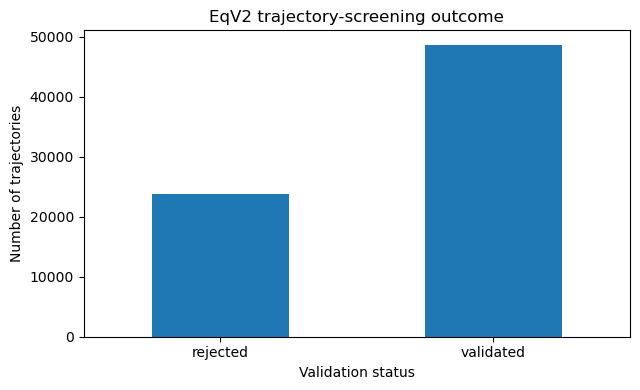

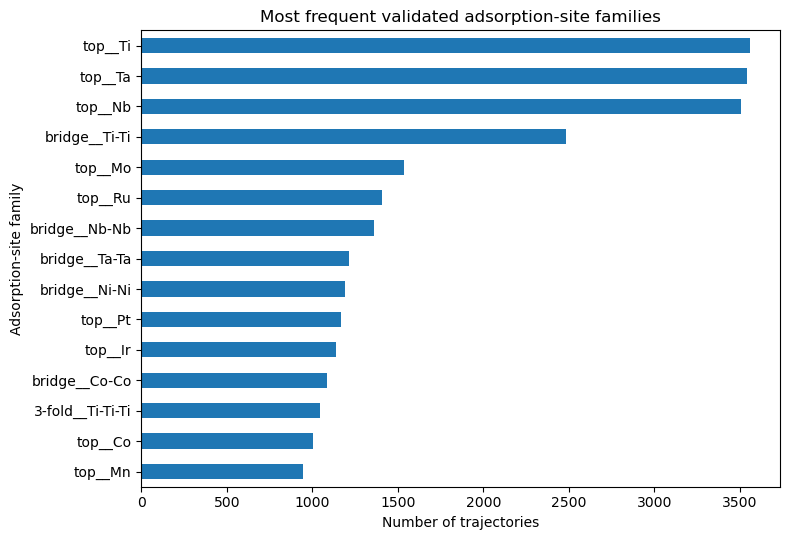

In [14]:
if MAKE_DISTRIBUTION_FIGURES:
    if not df_all_records.empty:
        ax = (
            df_all_records["validation_status"]
            .value_counts()
            .sort_index()
            .plot(kind="bar", figsize=(6.5, 4.0))
        )
        ax.set_title("EqV2 trajectory-screening outcome")
        ax.set_xlabel("Validation status")
        ax.set_ylabel("Number of trajectories")
        ax.tick_params(axis="x", rotation=0)
        plt.tight_layout()
        plt.show()

    assigned_sites = df_validated.loc[df_validated["unique_site_key"].notna()]
    if not assigned_sites.empty:
        ax = (
            assigned_sites["site_family"]
            .value_counts()
            .head(15)
            .sort_values()
            .plot(kind="barh", figsize=(8.0, 5.5))
        )
        ax.set_title("Most frequent validated adsorption-site families")
        ax.set_xlabel("Number of trajectories")
        ax.set_ylabel("Adsorption-site family")
        plt.tight_layout()
        plt.show()

## Inspect a global minimum

The first row of the global-minimum table shows the information available for each configuration that was evaluated by SP-DFT. Its trajectory is at `DATA_ROOT / trajectory_relative_path`.

In [ ]:
if df_global_minima.empty:
    print("No global minimum is available for the current selection.")
else:
    columns = [
        "system_id",
        "material_id",
        "facet",
        "adsorbate",
        "predicted_adsorption_energy_eV",
        "trajectory_order",
        "trajectory_label",
        "configuration_index",
        "trajectory_filename",
        "trajectory_file",
        "chemical_formula",
        "relative_energy_within_system_eV",
        "final_max_force_eV_per_A",
        "site_type",
        "neighbor_string",
        "neighbor_indices",
        "neighbor_distances_A",
        "neighbor_images",
        "binding_mode",
        "site_confidence",
        "site_reason",
    ]
    display(
        df_global_minima[
            [column for column in columns if column in df_global_minima.columns]
        ].head(1)
    )

## Output tables

| File | Content |
|---|---|
| `orr_eqv2_all_trajectory_quality_control.csv` | One row per trajectory, with `validation_status`, `rejection_reason`, `anomaly_detected`, and the four FairChem anomaly flags (`anomaly_adsorbate_dissociated`, `anomaly_adsorbate_desorbed`, `anomaly_surface_changed`, `anomaly_adsorbate_intercalated`) |
| `orr_eqv2_validated_relaxation_trajectories.csv` | Validated trajectories with energies, forces, site assignment, and energy rank within each system |
| `orr_eqv2_unique_adsorption_site_minima.csv` | Lowest-energy trajectory for each distinct site instance |
| `orr_eqv2_adsorption_site_family_minima.csv` | Lowest-energy trajectory for each site family (motif and coordinating elements) |
| `orr_eqv2_global_minimum_configuration_per_system.csv` | Lowest-energy configuration per slab–adsorbate system; these geometries were evaluated by SP-DFT |
| `orr_eqv2_quality_control_summary_by_system.csv` | Counts of validated and rejected trajectories per system, by reason |

`predicted_adsorption_energy_eV` is the OC20/EqV2 adsorption energy of the final frame, and `relative_energy_within_system_eV` its difference from the system minimum. Site columns: `site_type` is the first-shell motif, `neighbor_string` the coordinating
elements, and `site_confidence` is `review` for geometries that are noncanonical,
sensitive to the contact cutoff, or bound through both oxygens of OOH$^{*}$.

## Citation

If you use this notebook or the data, please cite the article and the Zenodo dataset
(https://doi.org/10.5281/zenodo.24310973). The anomaly checks use `DetectTrajAnomaly`
from the FairChem `fairchem-data-oc` package, and the trajectories were generated with
the OC20 EquiformerV2 model; please also cite the OC20 dataset and EquiformerV2 papers.